A NumPy indexing bug in the GNILC dust preprocessing means the CIB monopole was never actually subtracted from the intensity input used to build the PySM `d9`/`d10`/`d11` dust templates (reported by [@ginleaf](https://github.com/ginleaf) in [PySM issue #281](https://github.com/galsci/pysm/issues/281)). Before regenerating the templates, we need the real zero-level offset of that exact input map, measured with the standard HI column density correlation. This notebook does it: the GNILC F353 map, smoothed to 80 arcmin, regressed against the HI4PI N_HI map outside the Galactic plane on diffuse lines of sight. The answer is **+0.125 MJy/sr**, essentially the 0.13 MJy/sr the pipeline originally intended to subtract.

## Why this notebook

In the GNILC dust preprocessing (issue #281) the pipeline intended to subtract the CIB monopole,
0.13 MJy/sr (Planck 2018 XII, Sect. 2.2), from the intensity map outside the GAL080 mask.
Because of a NumPy indexing bug (the boolean mask was cast to `np.int_` and then used as an
index) the subtraction only ever modified 2 pixels out of 50 million, so the released
d9/d10/d11 dust templates carry the zero level of the input GNILC map unchanged.

Before regenerating the templates we need the actual isotropic offset of the **exact input map
used by the pipeline**: the 2015 (PR2) GNILC F353 map smoothed to 21.8 arcmin
(`COM_CompMap_Dust-GNILC-F353_2048_21p8acm.fits`). The 0.13 MJy/sr value was measured on the
Planck 2018 HFI **frequency** maps and need not apply to this product, whose zero level was set
independently by the GNILC processing.

This notebook measures that offset with the standard HI column density correlation method.

## How to run

This notebook is designed to run on an HPC compute node through Slurm (e.g. Perlmutter);
never execute it on a login node. Input locations are taken from environment variables so that
no personal path is hardcoded:

* `PYSM_DATA`: root of the public PySM data tree, default
  `/global/cfs/cdirs/cmb/www/pysm-data` on Perlmutter (served at
  https://portal.nersc.gov/project/cmb/pysm-data/)
* `HI4PI_FILENAME`: path to the HI4PI column density map, default `NHI_HPX.fits` in the current
  directory. Download once (data transfer on a login node is fine) from LAMBDA:
  https://lambda.gsfc.nasa.gov/data/foregrounds/HI4PI/NHI_HPX.fits
  (577 MB, HEALPix NSIDE 1024, RING, binary table with `HPXINDEX` and `NHI` columns in cm^-2,
  velocity range |v_LSR| < 600 km/s)

Execution results are written to a separate output notebook, this source notebook is preserved
without outputs.

## Method

At high Galactic latitude, on diffuse lines of sight, the thermal dust intensity at 353 GHz is
approximately proportional to the neutral hydrogen column density (Boulanger & Peraux 1988):

$$ I_{353}(p) = \epsilon_{353} \, N_{HI}(p) + I_{iso} $$

* $\epsilon_{353}$ is the dust emissivity per H atom (the slope of the relation),
* $I_{iso}$ is the isotropic term: CIB monopole, residual zodiacal emission, and any zero-level
  offset of the map (the intercept).

Hydrogen is an excellent tracer of the diffuse dust at high latitude, and, unlike the dust
intensity itself, it carries no cosmic infrared background, so the intercept of the relation is
a clean estimate of the isotropic emission component. This is the technique used by Planck to
set the zero level of dust maps, and it is what issue #281 recommends to determine the offset
for this specific input map.

The fit is restricted to:

* pixels outside the Planck GAL080 Galactic plane mask (the same mask used by the preprocessing
  pipeline), and
* diffuse lines of sight, $N_{HI} < 3 \times 10^{20}\ \mathrm{cm}^{-2}$ (the cut suggested in
  issue #281), and
* outliers are rejected with iterative sigma clipping (molecular clouds, residual compact
  sources and dust-HI decorrelation produce a non-Gaussian tail).

Both maps are smoothed to a common 80 arcmin beam and degraded to NSIDE 512 before the fit.

**Caveats** to keep in mind when reading the result: molecular gas (H$_2$) and ionized gas are
not traced by N_HI and partly end up in the intercept, the choice of the N_HI cut and of the
velocity range matters at the ~0.01 MJy/sr level, and residual CIB fluctuations average out
only approximately over the selected sky fraction.

In [1]:
import os
import json
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.table import Table

# Input data, override with environment variables when running elsewhere.
PYSM_DATA = Path(os.environ.get("PYSM_DATA", "/global/cfs/cdirs/cmb/www/pysm-data"))
GNILC_I353_FILENAME = PYSM_DATA / "dust_gnilc/inputs/COM_CompMap_Dust-GNILC-F353_2048_21p8acm.fits"
GAL080_MASK_FILENAME = PYSM_DATA / "dust_gnilc/raw/HFI_Mask_GalPlane-apo2_2048_R2.00_GAL080_noapo.fits.gz"
HI4PI_FILENAME = Path(os.environ.get("HI4PI_FILENAME", "NHI_HPX.fits"))

# Analysis configuration
NSIDE_ANALYSIS = 512   # common resolution for the regression
FWHM_ARCMIN = 80.0     # common beam applied to both maps before the fit
NHI_MAX = 3.0          # diffuse sightlines, N_HI < 3e20 cm^-2 (units of 1e20 cm^-2)
NSIGMA_CLIP = 3.0      # outlier rejection in the iterative fit
N_BOOTSTRAP = 200      # bootstrap realizations for the uncertainty

print("numpy", np.__version__, "| healpy", hp.__version__)
print("GNILC I353 input :", GNILC_I353_FILENAME)
print("GAL080 mask      :", GAL080_MASK_FILENAME)
print("HI4PI N_HI input :", HI4PI_FILENAME)

numpy 2.4.6 | healpy 1.20.1
GNILC I353 input : /mnt/home/azonca/issue_281/pysm-data/dust_gnilc/inputs/COM_CompMap_Dust-GNILC-F353_2048_21p8acm.fits
GAL080 mask      : /mnt/home/azonca/issue_281/pysm-data/dust_gnilc/raw/HFI_Mask_GalPlane-apo2_2048_R2.00_GAL080_noapo.fits.gz
HI4PI N_HI input : /mnt/home/azonca/issue_281/data/NHI_HPX.fits


## Load the input maps

* **GNILC F353, 21.8' beam**: the intensity input of the d9/d10/d11 preprocessing, in MJy/sr.
  This is the map whose zero level we want to measure.
* **HI4PI N_HI**: all-sky HI column density in cm^-2. The LAMBDA release is a FITS binary table
  with one record per HEALPix pixel (NSIDE 1024, RING ordering) and a `NHI` column.
* **GAL080 mask**: 1 outside the Galactic plane mask (about 79% of the sky), 0 inside; the same
  mask the preprocessing uses for the monopole subtraction.

In [2]:
# GNILC F353 intensity (PR2, 21.8 arcmin), in MJy/sr
i353_2048 = hp.read_map(GNILC_I353_FILENAME, dtype=np.float64)
print("GNILC I353: NSIDE", hp.get_nside(i353_2048))

# GAL080 mask: 1 outside the Galactic plane, 0 inside
gal080_2048 = hp.read_map(GAL080_MASK_FILENAME, dtype=np.float64)
print(f"GAL080: fraction of sky outside the plane = {gal080_2048.mean():.4f}")

# HI4PI N_HI: binary table with explicit pixel indices, NHI column in cm^-2
hi4pi_table = Table.read(HI4PI_FILENAME, hdu=1)
print("HI4PI columns:", hi4pi_table.colnames)
nside_hi = hp.npix2nside(len(hi4pi_table))
nhi_1024 = np.full(hp.nside2npix(nside_hi), np.nan)
nhi_1024[hi4pi_table["HPXINDEX"].astype(int)] = hi4pi_table["NHI"]
print(f"HI4PI: NSIDE {nside_hi}, {len(hi4pi_table):,} records, "
      f"{np.isnan(nhi_1024).sum()} missing pixels")
print(f"N_HI range: {np.nanmin(nhi_1024):.3e} to {np.nanmax(nhi_1024):.3e} cm^-2")

GNILC I353: NSIDE 2048


GAL080: fraction of sky outside the plane = 0.7913


HI4PI columns: ['HPXINDEX', 'RA2000', 'DEC2000', 'GLON', 'GLAT', 'NHI']
HI4PI: NSIDE 1024, 12,582,912 records, 0 missing pixels
N_HI range: -1.600e+21 to 2.398e+22 cm^-2


In [3]:
# Smooth both tracers to the same 80 arcmin beam and bring everything to NSIDE_ANALYSIS.
fwhm = np.radians(FWHM_ARCMIN / 60.0)

i353 = hp.ud_grade(hp.smoothing(i353_2048, fwhm=fwhm), nside_out=NSIDE_ANALYSIS)
nhi = hp.ud_grade(hp.smoothing(nhi_1024, fwhm=fwhm), nside_out=NSIDE_ANALYSIS)
outside_plane = hp.ud_grade(gal080_2048, nside_out=NSIDE_ANALYSIS) > 0.5

# N_HI in units of 1e20 cm^-2 for readable numbers
nhi = nhi / 1e20

# Regression domain: high latitude, diffuse, valid data
selection = outside_plane & (nhi < NHI_MAX) & np.isfinite(i353) & np.isfinite(nhi)
print(f"selection: {selection.sum():,} pixels of {selection.size:,} "
      f"({100 * selection.mean():.2f}% of the sky)")
print(f"N_HI in selection : {nhi[selection].min():.2f} to {nhi[selection].max():.2f} x 1e20 cm^-2")
print(f"I_353 in selection: median {np.median(i353[selection]):.3f} MJy/sr")

selection: 884,242 pixels of 3,145,728 (28.11% of the sky)
N_HI in selection : 0.57 to 3.00 x 1e20 cm^-2
I_353 in selection: median 0.190 MJy/sr


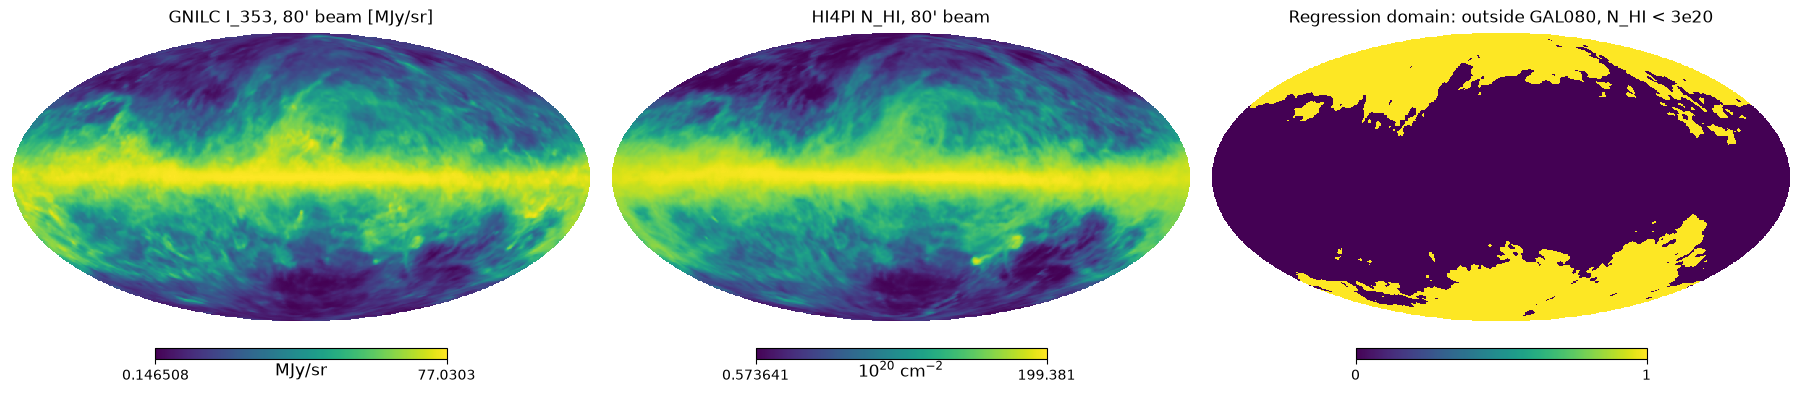

In [4]:
plt.figure(figsize=(18, 5))
hp.mollview(i353, sub=(1, 3, 1), title="GNILC I_353, 80' beam [MJy/sr]", unit="MJy/sr", norm="hist")
hp.mollview(nhi, sub=(1, 3, 2), title="HI4PI N_HI, 80' beam", unit=r"$10^{20}$ cm$^{-2}$", norm="hist")
hp.mollview(selection, sub=(1, 3, 3), title=f"Regression domain: outside GAL080, N_HI < {NHI_MAX:.0f}e20")
plt.show()

## Robust linear fit

Fit $I_{353} = \epsilon\, N_{HI} + I_{iso}$ on the selected pixels with iterative 3-sigma
clipping: at each iteration the outliers of the residual distribution are excluded and the fit
is repeated until the set of used pixels is stable. The uncertainty on slope and intercept is
estimated with a bootstrap over the retained pixels (the formal least-squares error would be
underestimated because neighboring pixels are correlated by the beam).

In [5]:
def robust_linear_fit(x, y, nsigma=NSIGMA_CLIP, n_iter=6):
    """Fit y = slope * x + intercept, rejecting outliers beyond nsigma at each iteration."""
    keep = np.ones(len(x), dtype=bool)
    for _ in range(n_iter):
        slope, intercept = np.polyfit(x[keep], y[keep], 1)
        residual = y - (slope * x + intercept)
        sigma = np.std(residual[keep])
        keep = np.abs(residual) < nsigma * sigma
    return slope, intercept, keep


x, y = nhi[selection], i353[selection]
slope, intercept, keep = robust_linear_fit(x, y)
print(f"pixels used after clipping: {int(keep.sum()):,} of {keep.size:,}")

# keep as a full-sky boolean mask, useful for the plots below
keep_sky = np.zeros(i353.size, dtype=bool)
keep_sky[np.where(selection)[0][keep]] = True

rng = np.random.default_rng(12345)
n_keep = int(keep.sum())
xf, yf = x[keep], y[keep]
slopes_boot = np.empty(N_BOOTSTRAP)
intercepts_boot = np.empty(N_BOOTSTRAP)
for i in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_keep, n_keep)
    slopes_boot[i], intercepts_boot[i] = np.polyfit(xf[idx], yf[idx], 1)

# express the offset also in uK_RJ at 353 GHz, the unit used by the preprocessing pipeline
try:
    import pysm3.units as pu

    offset_ukrj = (intercept * u.MJy / u.sr).to(
        pu.uK_RJ, equivalencies=pu.cmb_equivalencies(353 * u.GHz)
    )
except ImportError:
    offset_ukrj = (intercept * u.MJy / u.sr).to(
        u.uK, equivalencies=u.brightness_temperature(353 * u.GHz)
    )

print(f"dust emissivity slope: {slope:.4f} +/- {slopes_boot.std():.4f} MJy/sr per 1e20 cm^-2")
print(f"OFFSET (intercept)   : {intercept:+.4f} +/- {intercepts_boot.std():.4f} MJy/sr"
      f"  =  {offset_ukrj.value:+.2f} uK_RJ at 353 GHz")
print("for comparison: 0.13 MJy/sr = CIB monopole intended by the preprocessing,")
print("                ~0.06 MJy/sr = order of magnitude guessed in issue #281")

with open("gnilc_dust_offset_results.json", "w") as f:
    json.dump(
        {
            "slope_mjysr_per_1e20": float(slope),
            "intercept_mjysr": float(intercept),
            "intercept_mjysr_err": float(intercepts_boot.std()),
            "intercept_ukrj_353": float(offset_ukrj.value),
            "nhi_max_1e20": NHI_MAX,
            "fwhm_arcmin": FWHM_ARCMIN,
            "nside": NSIDE_ANALYSIS,
        },
        f,
        indent=2,
    )

pixels used after clipping: 857,201 of 884,242


dust emissivity slope: 0.0377 +/- 0.0000 MJy/sr per 1e20 cm^-2
OFFSET (intercept)   : +0.1254 +/- 0.0000 MJy/sr  =  +32.76 uK_RJ at 353 GHz
for comparison: 0.13 MJy/sr = CIB monopole intended by the preprocessing,
                ~0.06 MJy/sr = order of magnitude guessed in issue #281


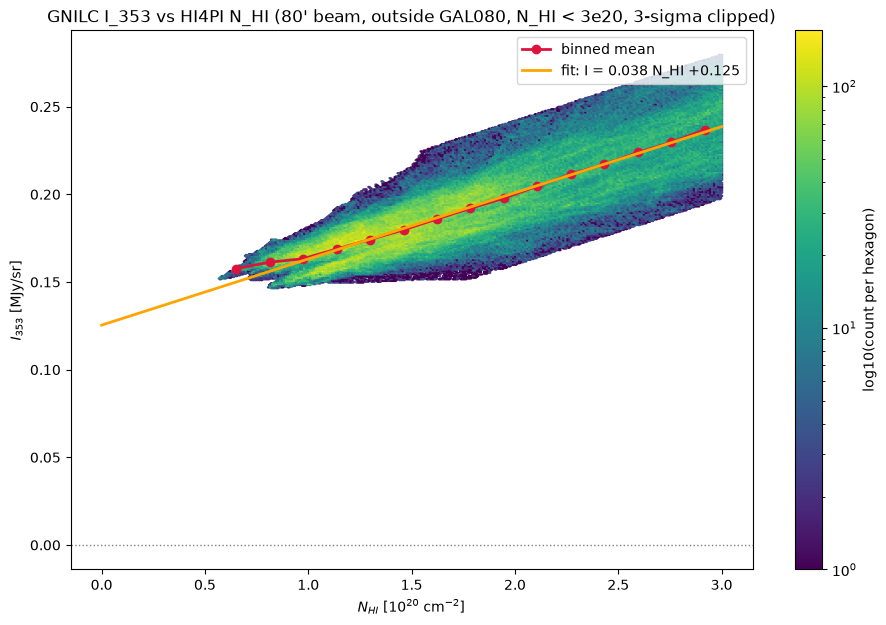

In [6]:
fig, ax = plt.subplots(figsize=(11, 7))
hb = ax.hexbin(xf, yf, gridsize=250, bins="log", cmap="viridis", mincnt=1)
fig.colorbar(hb, ax=ax, label="log10(count per hexagon)")

# binned means to check the linearity of the relation
nbins = 15
bins = np.linspace(xf.min(), xf.max(), nbins + 1)
centers = 0.5 * (bins[:-1] + bins[1:])
means = np.array([yf[(xf >= bins[i]) & (xf < bins[i + 1])].mean() for i in range(nbins)])
ax.plot(centers, means, "o-", color="crimson", lw=2, label="binned mean")

xx = np.linspace(0, xf.max(), 10)
ax.plot(xx, slope * xx + intercept, "-", color="orange", lw=2,
        label=f"fit: I = {slope:.3f} N_HI {intercept:+.3f}")
ax.axhline(0.0, color="gray", ls=":", lw=1)
ax.set_xlabel(r"$N_{HI}$ [$10^{20}$ cm$^{-2}$]")
ax.set_ylabel(r"$I_{353}$ [MJy/sr]")
ax.set_title(f"GNILC I_353 vs HI4PI N_HI ({FWHM_ARCMIN:.0f}' beam, outside GAL080, "
             f"N_HI < {NHI_MAX:.0f}e20, 3-sigma clipped)")
ax.legend()
plt.show()

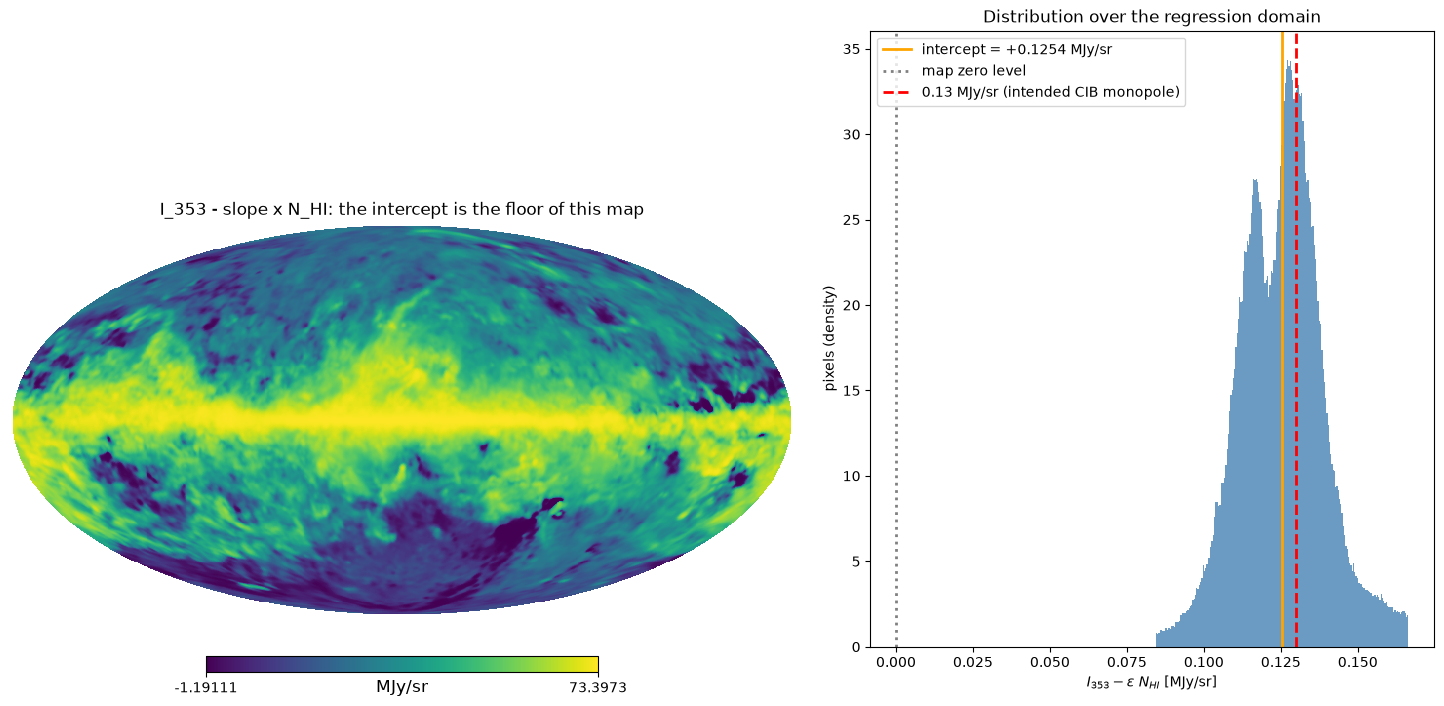

In [7]:
# Remove the HI-correlated part: what is left is the isotropic floor plus real
# dust-HI decorrelation (and the Galactic plane, outside the regression domain).
residual_iso = i353 - slope * nhi

plt.figure(figsize=(16, 8))
hp.mollview(
    residual_iso, sub=(1, 2, 1), unit="MJy/sr", norm="hist",
    title=r"I_353 - slope x N_HI: the intercept is the floor of this map",
)

plt.subplot(1, 2, 2)
plt.hist(residual_iso[keep_sky], bins=200, density=True, color="steelblue", alpha=0.8)
plt.axvline(intercept, color="orange", lw=2, label=f"intercept = {intercept:+.4f} MJy/sr")
plt.axvline(0.0, color="gray", ls=":", lw=2, label="map zero level")
plt.axvline(0.13, color="red", ls="--", lw=2, label="0.13 MJy/sr (intended CIB monopole)")
plt.xlabel(r"$I_{353} - \epsilon\ N_{HI}$ [MJy/sr]")
plt.ylabel("pixels (density)")
plt.title("Distribution over the regression domain")
plt.legend()
plt.show()

In [8]:
# Robustness: repeat the fit for different N_HI cuts and with an extra latitude cut.
theta, phi = hp.pix2ang(NSIDE_ANALYSIS, np.arange(hp.nside2npix(NSIDE_ANALYSIS)))
glat = 90.0 - np.degrees(theta)

print(f"{'cut':>28} {'pixels':>12} {'slope':>8} {'intercept':>10}")
for nhi_max in [2.0, 3.0, 4.0, 5.0]:
    sel_k = outside_plane & (nhi < nhi_max) & np.isfinite(i353)
    s, b, k = robust_linear_fit(nhi[sel_k], i353[sel_k])
    print(f"{f'outside GAL080, N_HI < {nhi_max:.0f}e20':>28} {int(k.sum()):>12,} "
          f"{s:>8.4f} {b:>+10.4f}")
for nhi_max in [2.0, 3.0]:
    sel_k = (np.abs(glat) > 30.0) & (nhi < nhi_max) & np.isfinite(i353)
    s, b, k = robust_linear_fit(nhi[sel_k], i353[sel_k])
    print(f"{f'|b| > 30 deg, N_HI < {nhi_max:.0f}e20':>28} {int(k.sum()):>12,} "
          f"{s:>8.4f} {b:>+10.4f}")

                         cut       pixels    slope  intercept


 outside GAL080, N_HI < 2e20      536,863   0.0343    +0.1300


 outside GAL080, N_HI < 3e20      857,201   0.0377    +0.1254


 outside GAL080, N_HI < 4e20    1,170,368   0.0420    +0.1188


 outside GAL080, N_HI < 5e20    1,442,914   0.0443    +0.1144


   |b| > 30 deg, N_HI < 2e20      536,300   0.0343    +0.1300


   |b| > 30 deg, N_HI < 3e20      834,298   0.0371    +0.1262


## Reading the result

The intercept printed above is the estimate of the **isotropic offset of the GNILC F353 input
map**: the sum of the CIB monopole, residual zodiacal emission, and any zero-level offset
introduced by the GNILC processing. It is the quantity that the preprocessing should subtract
from the intensity map outside the Galactic plane, in place of the 0.13 MJy/sr that was
originally intended for the Planck 2018 HFI frequency maps.

Things to check in the outputs above:

* the robustness table: the intercept should be stable at the few x 0.01 MJy/sr level across the
  N_HI cuts; a strong trend would indicate that dust-HI decorrelation or molecular gas is
  biasing the fit, and the lowest, most diffuse cut is the most trustworthy;
* the binned means in the scatter plot: the relation should be linear over the selected range;
* the residual map: outside the Galactic plane it should be close to uniform with a floor at the
  intercept value.

Remember that the correction cannot be applied by simply subtracting a constant from the
already-released d9/d10/d11 templates: the preprocessing works in logpoltens space, so the
offset also affects the polarization fraction and the small-scale modulation. The templates
need to be regenerated from the input maps with the fixed code and the offset measured here.

## References

* Boulanger & Peraux 1988, ApJ 330, 964: dust-HI correlation and the estimate of the isotropic
  infrared component
* HI4PI Collaboration 2016, A&A 594, A116: the HI4PI survey and the N_HI map
* Planck Collaboration 2018 XII: CIB monopole of 0.13 MJy/sr in the HFI frequency maps
* PySM issue #281: the indexing bug and the impact on the GNILC dust templates